## Section 1: Setup & Imports
Set up the environment and import required libraries. Add project root to sys.path.

In [2]:
import sys
from pathlib import Path

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf

from src.utils.config import *
from src.data.loader import (
    discover_wav_files,
    create_metadata_dataframe,
    save_metadata,
)
from src.data.preprocessing import get_audio_info
from src.features.audio_features import plot_waveform, plot_mel_spectrogram

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline

print(f"Project root: {project_root}")
print(f"UASpeech audio dir: {UASPEECH_AUDIO_DIR}")
print(f"Audio dir exists: {UASPEECH_AUDIO_DIR.exists()}")

Project root: e:\
UASpeech audio dir: E:\speech disorder gp\data\raw\UASpeech\audio\noisereduce
Audio dir exists: True


## Section 2: Dataset Discovery
Discover all WAV files in the dataset directory.

In [3]:
# Discover all WAV files
wav_files = discover_wav_files()
print(f"\nTotal WAV files found: {len(wav_files)}")
print(f"\nFirst 10 files:")
for f in wav_files[:10]:
    print(f"  {f.name}")
print(f"\nLast 5 files:")
for f in wav_files[-5:]:
    print(f"  {f.name}")

Found 143298 WAV files under E:\speech disorder gp\data\raw\UASpeech\audio\noisereduce

Total WAV files found: 143298

First 10 files:
  CF02_B1_C10_M2.wav
  CF02_B1_C10_M3.wav
  CF02_B1_C10_M4.wav
  CF02_B1_C10_M5.wav
  CF02_B1_C10_M6.wav
  CF02_B1_C10_M7.wav
  CF02_B1_C10_M8.wav
  CF02_B1_C11_M2.wav
  CF02_B1_C11_M3.wav
  CF02_B1_C11_M4.wav

Last 5 files:
  M16_B3_UW9_M4.wav
  M16_B3_UW9_M5.wav
  M16_B3_UW9_M6.wav
  M16_B3_UW9_M7.wav
  M16_B3_UW9_M8.wav


## Section 3: Parse Filenames & Create Metadata
Parse the filenames to extract metadata and create a pandas DataFrame.

In [4]:
# Parse all filenames and create metadata DataFrame
metadata_df, malformed_df = create_metadata_dataframe(wav_files)

print(f"\nMetadata shape: {metadata_df.shape}")
print(f"\nColumn dtypes:")
print(metadata_df.dtypes)
print(f"\nFirst 10 rows:")
metadata_df.head(10)

Valid filenames:     143290
Malformed filenames: 8

Metadata shape: (143290, 8)

Column dtypes:
filepath        str
filename        str
speaker         str
block           str
word            str
microphone      str
label         int64
label_name      str
dtype: object

First 10 rows:


,filepath,filename,speaker,block,word,microphone,label,label_name
0,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M2.wav,CF02,B1,C10,M2,0,Control
1,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M3.wav,CF02,B1,C10,M3,0,Control
2,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M4.wav,CF02,B1,C10,M4,0,Control
3,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M5.wav,CF02,B1,C10,M5,0,Control
4,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M6.wav,CF02,B1,C10,M6,0,Control
5,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M7.wav,CF02,B1,C10,M7,0,Control
6,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M8.wav,CF02,B1,C10,M8,0,Control
7,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C11_M2.wav,CF02,B1,C11,M2,0,Control
8,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C11_M3.wav,CF02,B1,C11,M3,0,Control
9,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C11_M4.wav,CF02,B1,C11,M4,0,Control


In [5]:
# Check malformed filenames
if len(malformed_df) > 0:
    print(f"\n⚠ {len(malformed_df)} malformed filenames found:")
    print(malformed_df.head(20))
else:
    print("✓ No malformed filenames found")

# Check for duplicate file paths
duplicates = metadata_df['filepath'].duplicated().sum()
print(f"\nDuplicate file paths: {duplicates}")


⚠ 8 malformed filenames found:
                                            filepath             filename
0  E:\speech disorder gp\data\raw\UASpeech\audio\...  ._CM12_B1_C2_M8.wav
1  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F02_B1_C1_M3.wav
2  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F03_B1_C1_M3.wav
3  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F03_B1_C1_M8.wav
4  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F03_B1_C2_M8.wav
5  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F04_B1_C1_M3.wav
6  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._F05_B1_C1_M3.wav
7  E:\speech disorder gp\data\raw\UASpeech\audio\...   ._M01_B1_C1_M3.wav

Duplicate file paths: 0


## Section 4: Label Verification
Verify class labels mapping and speaker distribution.

In [6]:
# Label mapping documentation
print("Label Mapping:")
print(f"  {LABEL_CONTROL} → {LABEL_MAP[LABEL_CONTROL]}")
print(f"  {LABEL_DYSARTHRIC} → {LABEL_MAP[LABEL_DYSARTHRIC]}")

# Verify labels
print(f"\nUnique labels: {sorted(metadata_df['label'].unique())}")
print(f"Unique label names: {sorted(metadata_df['label_name'].unique())}")

# Show speaker to label mapping
speaker_labels = metadata_df[['speaker', 'label_name']].drop_duplicates().sort_values('speaker')
print(f"\nSpeaker → Label mapping ({len(speaker_labels)} speakers):")
for _, row in speaker_labels.iterrows():
    print(f"  {row['speaker']:>5} → {row['label_name']}")

Label Mapping:
  0 → Control
  1 → Dysarthric

Unique labels: [np.int64(0), np.int64(1)]
Unique label names: ['Control', 'Dysarthric']

Speaker → Label mapping (28 speakers):
   CF02 → Control
   CF03 → Control
   CF04 → Control
   CF05 → Control
   CM01 → Control
   CM04 → Control
   CM05 → Control
   CM06 → Control
   CM08 → Control
   CM09 → Control
   CM10 → Control
   CM12 → Control
   CM13 → Control
    F02 → Dysarthric
    F03 → Dysarthric
    F04 → Dysarthric
    F05 → Dysarthric
    M01 → Dysarthric
    M04 → Dysarthric
    M05 → Dysarthric
    M07 → Dysarthric
    M08 → Dysarthric
    M09 → Dysarthric
    M10 → Dysarthric
    M11 → Dysarthric
    M12 → Dysarthric
    M14 → Dysarthric
    M16 → Dysarthric


## Section 5: Dataset Statistics
Show overall dataset statistics, counts by speaker, block, and microphone.

In [7]:
print("=" * 60)
print("DATASET STATISTICS")
print("=" * 60)
print(f"1. Total WAV files:        {len(metadata_df)}")
print(f"2. Unique speakers:        {metadata_df['speaker'].nunique()}")
print(f"3. Control speakers:       {metadata_df[metadata_df['label']==0]['speaker'].nunique()}")
print(f"4. Dysarthric speakers:    {metadata_df[metadata_df['label']==1]['speaker'].nunique()}")
print(f"5. Samples per class:")
for name, count in metadata_df['label_name'].value_counts().items():
    print(f"   {name}: {count}")
print(f"6. Unique blocks:          {sorted(metadata_df['block'].unique())}")
print(f"7. Unique microphones:     {sorted(metadata_df['microphone'].unique())}")
print(f"8. Unique words:           {metadata_df['word'].nunique()}")
print(f"9. Malformed filenames:    {len(malformed_df)}")
print(f"10. Duplicate file paths:  {metadata_df['filepath'].duplicated().sum()}")

DATASET STATISTICS
1. Total WAV files:        143290
2. Unique speakers:        28
3. Control speakers:       13
4. Dysarthric speakers:    15
5. Samples per class:
   Dysarthric: 73675
   Control: 69615
6. Unique blocks:          ['B1', 'B2', 'B3']
7. Unique microphones:     ['M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8']
8. Unique words:           255
9. Malformed filenames:    8
10. Duplicate file paths:  0


In [8]:
# Samples per speaker
speaker_counts = metadata_df.groupby(['speaker', 'label_name']).size().reset_index(name='count')
speaker_counts = speaker_counts.sort_values('count', ascending=False)
print("\nSamples per speaker:")
for _, row in speaker_counts.iterrows():
    print(f"  {row['speaker']:>5} ({row['label_name']:>10}): {row['count']}")


Samples per speaker:
   CF02 (   Control): 5355
   CF03 (   Control): 5355
   CF04 (   Control): 5355
   CF05 (   Control): 5355
   CM01 (   Control): 5355
   CM04 (   Control): 5355
   CM05 (   Control): 5355
   CM06 (   Control): 5355
   CM08 (   Control): 5355
   CM09 (   Control): 5355
   CM10 (   Control): 5355
   CM12 (   Control): 5355
   CM13 (   Control): 5355
    F02 (Dysarthric): 5355
    M05 (Dysarthric): 5355
    F05 (Dysarthric): 5355
    M10 (Dysarthric): 5355
    M09 (Dysarthric): 5355
    M08 (Dysarthric): 5355
    M07 (Dysarthric): 5355
    M14 (Dysarthric): 5355
    F04 (Dysarthric): 5251
    F03 (Dysarthric): 5184
    M11 (Dysarthric): 4590
    M12 (Dysarthric): 4590
    M16 (Dysarthric): 4590
    M04 (Dysarthric): 3825
    M01 (Dysarthric): 2805


In [9]:
print("\nSamples per block:")
print(metadata_df['block'].value_counts().sort_index())


Samples per block:
block
B1    47862
B2    47912
B3    47516
Name: count, dtype: int64


In [10]:
print("\nSamples per microphone:")
print(metadata_df['microphone'].value_counts().sort_index())


Samples per microphone:
microphone
M2    17555
M3    21126
M4    19851
M5    21381
M6    21381
M7    21381
M8    20615
Name: count, dtype: int64


## Section 6: Visualizations
Visualize class distribution, speakers, blocks, and microphones.

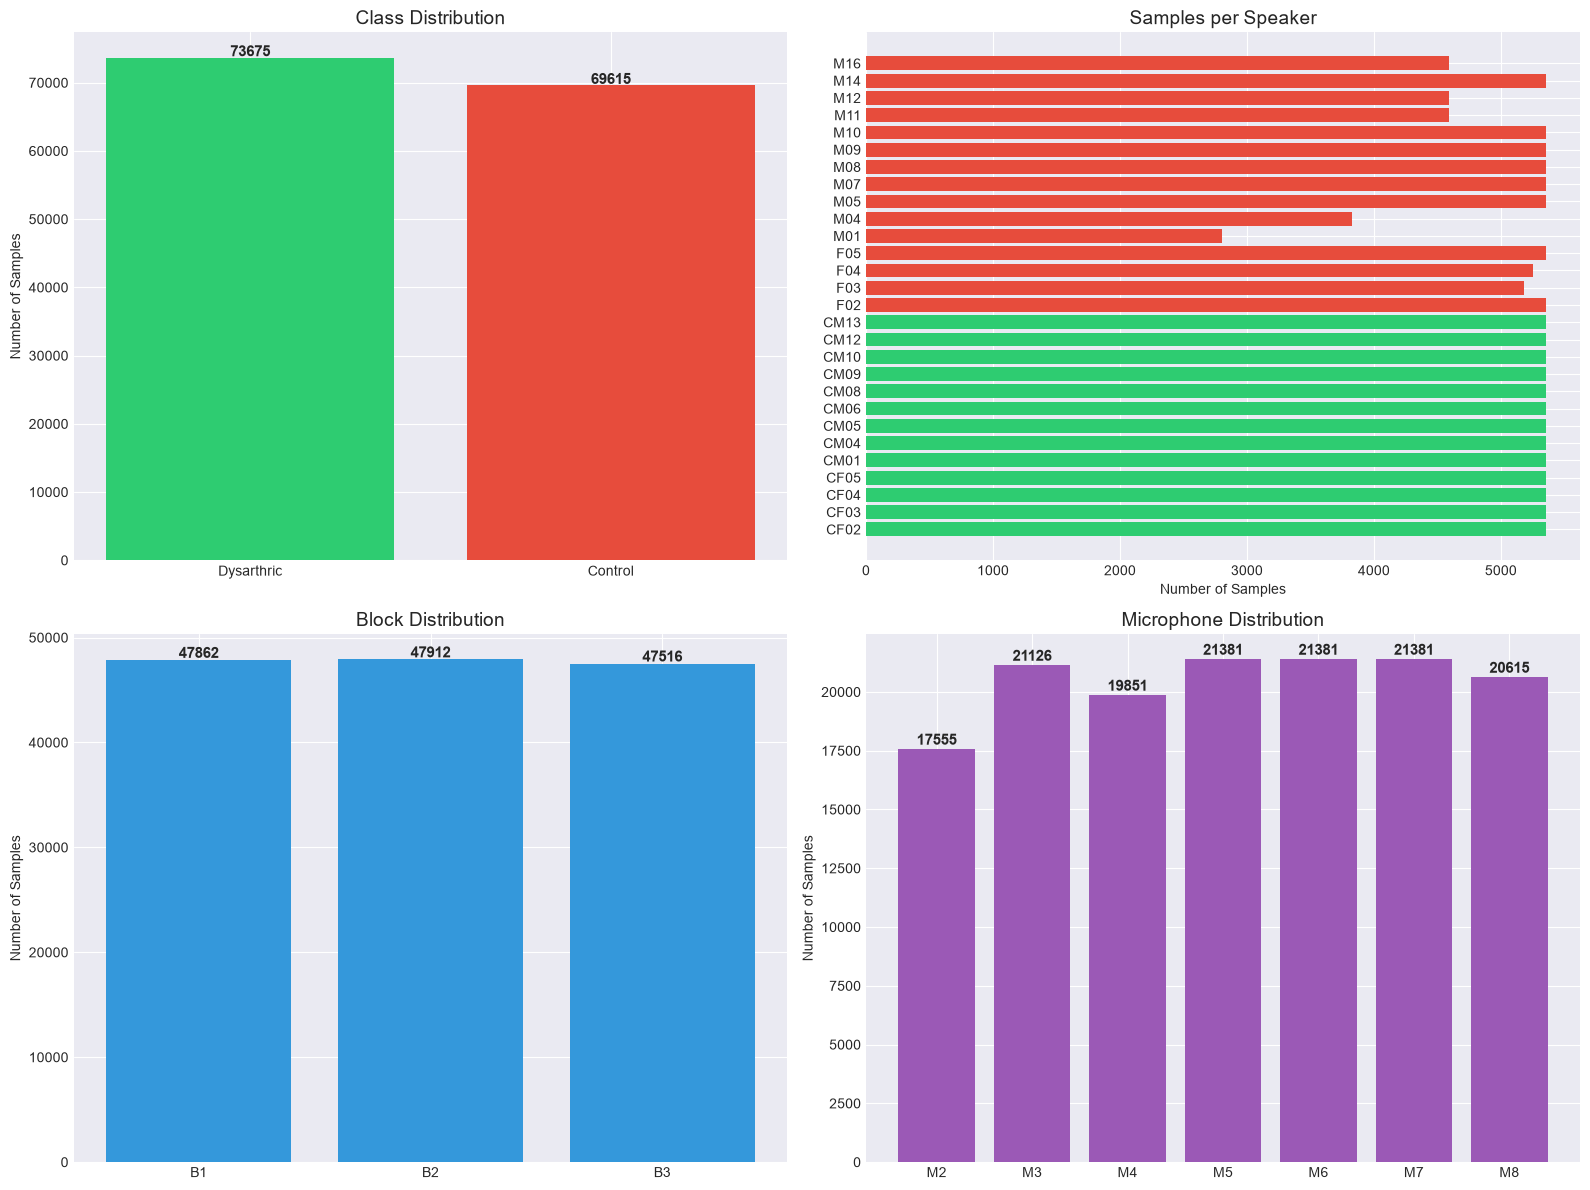

Saved: E:\speech disorder gp\outputs\figures\dataset_distributions.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Class distribution
class_counts = metadata_df['label_name'].value_counts()
axes[0, 0].bar(class_counts.index, class_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0, 0].set_title('Class Distribution', fontsize=14)
axes[0, 0].set_ylabel('Number of Samples')
for i, (cls, cnt) in enumerate(class_counts.items()):
    axes[0, 0].text(i, cnt + 200, str(cnt), ha='center', fontsize=11, fontweight='bold')

# 2. Speaker distribution
speaker_data = metadata_df.groupby(['speaker', 'label_name']).size().reset_index(name='count')
speaker_data = speaker_data.sort_values(['label_name', 'speaker'])
colors = ['#2ecc71' if l == 'Control' else '#e74c3c' for l in speaker_data['label_name']]
axes[0, 1].barh(speaker_data['speaker'], speaker_data['count'], color=colors)
axes[0, 1].set_title('Samples per Speaker', fontsize=14)
axes[0, 1].set_xlabel('Number of Samples')

# 3. Block distribution
block_counts = metadata_df['block'].value_counts().sort_index()
axes[1, 0].bar(block_counts.index, block_counts.values, color='#3498db')
axes[1, 0].set_title('Block Distribution', fontsize=14)
axes[1, 0].set_ylabel('Number of Samples')
for i, (blk, cnt) in enumerate(block_counts.items()):
    axes[1, 0].text(i, cnt + 200, str(cnt), ha='center', fontsize=11, fontweight='bold')

# 4. Microphone distribution
mic_counts = metadata_df['microphone'].value_counts().sort_index()
axes[1, 1].bar(mic_counts.index, mic_counts.values, color='#9b59b6')
axes[1, 1].set_title('Microphone Distribution', fontsize=14)
axes[1, 1].set_ylabel('Number of Samples')
for i, (mic, cnt) in enumerate(mic_counts.items()):
    axes[1, 1].text(i, cnt + 200, str(cnt), ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'dataset_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR / 'dataset_distributions.png'}")

## Section 7: Audio Inspection
Check audio file metadata such as sample rate, channels, and duration.

In [12]:
# Sample files from each class
control_files = metadata_df[metadata_df['label'] == 0].sample(5, random_state=42)
dysarthric_files = metadata_df[metadata_df['label'] == 1].sample(5, random_state=42)

print("=" * 60)
print("AUDIO INSPECTION")
print("=" * 60)

all_sample_rates = set()
all_channels = set()

for name, sample_df in [('Control', control_files), ('Dysarthric', dysarthric_files)]:
    print(f"\n--- {name} Samples ---")
    for _, row in sample_df.iterrows():
        info = get_audio_info(row['filepath'])
        all_sample_rates.add(info['sample_rate'])
        all_channels.add(info['channels'])
        print(f"  {row['filename']}:")
        print(f"    Sample Rate: {info['sample_rate']} Hz")
        print(f"    Channels:    {info['channels']}")
        print(f"    Duration:    {info['duration']:.3f} sec")
        print(f"    Frames:      {info['frames']}")

print(f"\n\nUnique sample rates found: {all_sample_rates}")
print(f"Unique channel configs: {all_channels}")

AUDIO INSPECTION

--- Control Samples ---
  CM06_B3_UW89_M7.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    1.533 sec
    Frames:      24532
  CF03_B2_CW2_M6.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    1.622 sec
    Frames:      25951
  CF03_B3_LY_M4.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    1.859 sec
    Frames:      29751
  CM13_B3_CW64_M6.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    1.521 sec
    Frames:      24334
  CM09_B1_CW14_M8.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    1.462 sec
    Frames:      23386

--- Dysarthric Samples ---
  M14_B3_CW60_M7.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    2.379 sec
    Frames:      38061
  M01_B3_LX_M6.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    4.220 sec
    Frames:      67520
  M16_B2_UW84_M3.wav:
    Sample Rate: 16000 Hz
    Channels:    1
    Duration:    2.409 sec
    Frames:      

In [13]:
# Check sample rates across a larger sample
import random
random.seed(42)
sample_indices = random.sample(range(len(metadata_df)), min(500, len(metadata_df)))
sampled_files = metadata_df.iloc[sample_indices]

sr_counts = {}
ch_counts = {}
durations = []

for _, row in sampled_files.iterrows():
    try:
        info = get_audio_info(row['filepath'])
        sr = info['sample_rate']
        ch = info['channels']
        sr_counts[sr] = sr_counts.get(sr, 0) + 1
        ch_counts[ch] = ch_counts.get(ch, 0) + 1
        durations.append(info['duration'])
    except Exception as e:
        print(f"Error reading {row['filename']}: {e}")

print(f"\nSample rate distribution (from {len(durations)} files):")
for sr, cnt in sorted(sr_counts.items()):
    print(f"  {sr} Hz: {cnt} files")

print(f"\nChannel distribution:")
for ch, cnt in sorted(ch_counts.items()):
    print(f"  {ch} channel(s): {cnt} files")

print(f"\nDuration statistics (seconds):")
durations = np.array(durations)
print(f"  Min:    {durations.min():.3f}")
print(f"  Max:    {durations.max():.3f}")
print(f"  Mean:   {durations.mean():.3f}")
print(f"  Median: {np.median(durations):.3f}")
print(f"  Std:    {durations.std():.3f}")
print(f"  95th percentile: {np.percentile(durations, 95):.3f}")
print(f"  99th percentile: {np.percentile(durations, 99):.3f}")


Sample rate distribution (from 500 files):
  16000 Hz: 500 files

Channel distribution:
  1 channel(s): 500 files

Duration statistics (seconds):
  Min:    1.141
  Max:    13.112
  Mean:   2.409
  Median: 2.044
  Std:    1.264
  95th percentile: 4.788
  99th percentile: 7.823


## Section 8: Waveform Visualizations
Visualize waveforms of sample control and dysarthric speech.

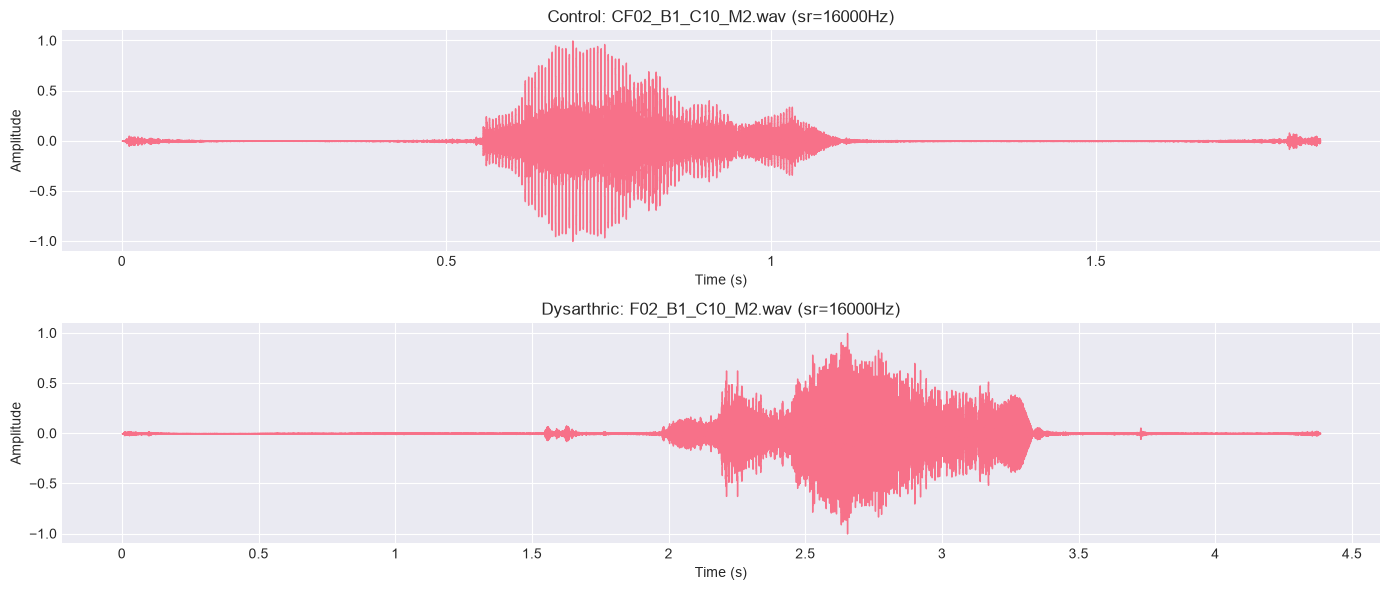

Saved: E:\speech disorder gp\outputs\figures\waveform_comparison.png


In [14]:
# Waveform visualization - Control vs Dysarthric
control_sample = metadata_df[metadata_df['label'] == 0].iloc[0]
dysarthric_sample = metadata_df[metadata_df['label'] == 1].iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

audio_c, sr_c = librosa.load(control_sample['filepath'], sr=None, mono=True)
plot_waveform(audio_c, sr_c, 
              title=f"Control: {control_sample['filename']} (sr={sr_c}Hz)", 
              ax=axes[0])

audio_d, sr_d = librosa.load(dysarthric_sample['filepath'], sr=None, mono=True)
plot_waveform(audio_d, sr_d, 
              title=f"Dysarthric: {dysarthric_sample['filename']} (sr={sr_d}Hz)", 
              ax=axes[1])

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'waveform_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR / 'waveform_comparison.png'}")

## Section 9: Duration Distribution
Histogram of audio file durations.

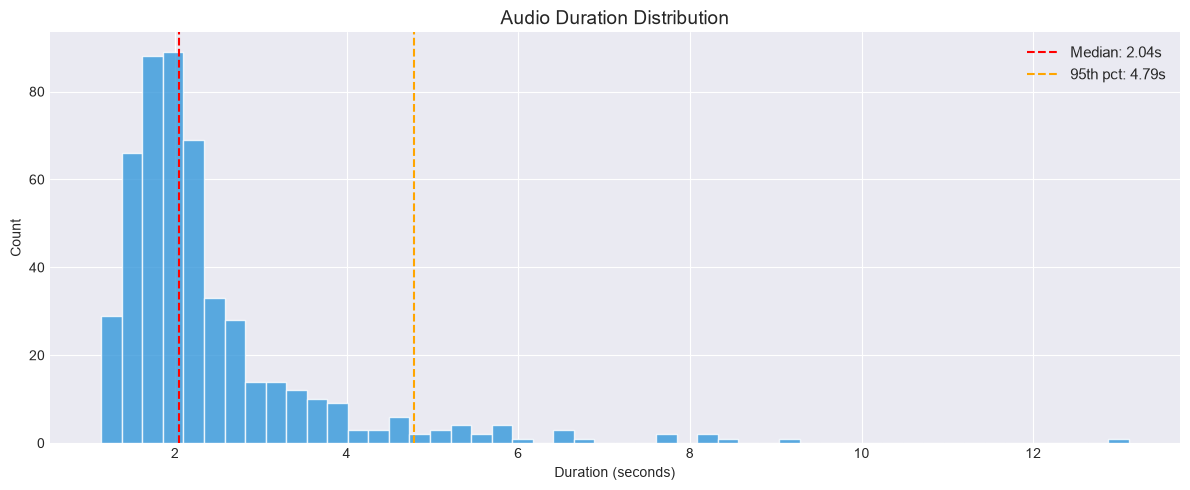

In [15]:
# Duration distribution histogram
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(durations, bins=50, color='#3498db', edgecolor='white', alpha=0.8)
ax.axvline(np.median(durations), color='red', linestyle='--', label=f'Median: {np.median(durations):.2f}s')
ax.axvline(np.percentile(durations, 95), color='orange', linestyle='--', label=f'95th pct: {np.percentile(durations, 95):.2f}s')
ax.set_title('Audio Duration Distribution', fontsize=14)
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Count')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'duration_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 10: Save Metadata
Save the finalized metadata DataFrame to a CSV file for subsequent steps.

In [16]:
# Save metadata to CSV
save_metadata(metadata_df)
print(f"\nMetadata saved to: {METADATA_CSV}")
print(f"Total valid records: {len(metadata_df)}")
print(f"\nDone! Proceed to 02_audio_preprocessing.ipynb")

Saved metadata to E:\speech disorder gp\data\metadata\uaspeech_metadata.csv (143290 rows)

Metadata saved to: E:\speech disorder gp\data\metadata\uaspeech_metadata.csv
Total valid records: 143290

Done! Proceed to 02_audio_preprocessing.ipynb
